<a href="https://colab.research.google.com/github/mehmetgul/ksu-data-wh-mining/blob/main/CS7050_Assignment3_Normalization_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 7050 – Assignment 3: Z-score Normalization & Clustering

**Dataset:** `mesocyclone.arff` (Doppler-radar mesocyclone measurements – 13 real attributes + `class`).

**How to run in Google Colab:** *Runtime → Run all*. If `mesocyclone.arff` is not already in the Colab working directory, the driver cell will ask you to upload it.

Everything that matters is written by hand – the z-score formula, Lloyd's k-means, bisecting k-means, SSE and the silhouette coefficient. NumPy is used only for array/matrix manipulation and matplotlib for the plots.

**Notebook layout**
0. Locating the data file
1. ARFF parsing
2. **Question 1** – z-score normalization
3. Shared clustering utilities (distance, SSE, silhouette)
4. **Question 2a** – basic K-means
5. **Question 2b** – bisecting K-means
6. Reporting helpers
7. Driver: 4 runs (K-means / bisecting × raw / normalized), k = 3…6, best k selected
8. Discussion

In [ ]:
"""
CS 7050 - Assignment 3: Z-score Normalization and Clustering (K-means / Bisecting K-means)
Dataset: mesocyclone.arff (Doppler radar mesocyclone measurements, 13 real attributes + class)

All core algorithms (z-score, k-means, bisecting k-means, SSE, silhouette) are written
from scratch. NumPy is used only for array/matrix manipulation, matplotlib for plots.
"""

import os
import re
import numpy as np
import matplotlib.pyplot as plt

## 0. Locating the data file
Looks for `mesocyclone.arff` next to the notebook; inside Colab it prompts for an upload if the file is missing.

In [ ]:
DATA_FILE = "mesocyclone.arff"


def locate_data_file(filename=DATA_FILE):
    """Return a path to the ARFF file. In Google Colab, prompt an upload if it is missing."""
    candidates = [filename, os.path.join("/mnt/user-data/uploads", filename),
                  os.path.join("/content", filename)]
    for path in candidates:
        if os.path.exists(path):
            return path
    try:                                   # running inside Google Colab
        from google.colab import files     # noqa: F401
        print(f"'{filename}' not found - please upload it now.")
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith(".arff"):
                return name
    except ImportError:
        pass
    raise FileNotFoundError(f"Could not find {filename}. Place it next to this notebook.")

## 1. ARFF parsing
A minimal reader: attribute names come from `@attribute` lines, data rows start after `@data` and may be separated by commas or whitespace.

In [ ]:
def load_arff(path):
    """
    Minimal ARFF reader.
    Returns (attribute_names, data_matrix) where data_matrix is a float ndarray
    with one row per pattern vector. Values may be separated by commas or spaces.
    """
    attribute_names = []
    rows = []
    in_data_section = False

    with open(path, "r") as handle:
        for raw_line in handle:
            line = raw_line.strip()
            if not line or line.startswith("%"):          # blank line or ARFF comment
                continue
            if not in_data_section:
                lowered = line.lower()
                if lowered.startswith("@attribute"):
                    # "@attribute name type" -> keep the name token
                    attribute_names.append(line.split()[1])
                elif lowered.startswith("@data"):
                    in_data_section = True
                continue
            # data section: split on commas and/or whitespace
            tokens = [tok for tok in re.split(r"[,\s]+", line) if tok]
            rows.append([float(tok) for tok in tokens])

    return attribute_names, np.array(rows, dtype=float)

## 2. Question 1 – Z-score normalization
$z = \dfrac{x - \mu}{\sigma}$ per attribute. Mean and (population) standard deviation are computed manually. The `class` attribute is excluded by the driver before this function is called.

In [ ]:
def zscore_normalize(data):
    """
    z = (x - mean) / std, computed column by column.
    mean and std are computed manually (population standard deviation).
    Columns with zero variance are left at 0 to avoid division by zero.
    Returns (normalized_data, means, stds).
    """
    n_rows, n_cols = data.shape
    means = np.zeros(n_cols)
    stds = np.zeros(n_cols)

    for col in range(n_cols):
        column = data[:, col]
        col_mean = column.sum() / n_rows
        col_var = ((column - col_mean) ** 2).sum() / n_rows
        means[col] = col_mean
        stds[col] = col_var ** 0.5

    normalized = np.zeros_like(data)
    for col in range(n_cols):
        if stds[col] > 0:
            normalized[:, col] = (data[:, col] - means[col]) / stds[col]
        else:
            normalized[:, col] = 0.0
    return normalized, means, stds

## 3. Shared clustering utilities
Euclidean distance to centroids, within-cluster SSE, and the mean silhouette coefficient (all hand-written).

In [ ]:
def euclidean_to_centroids(points, centroids):
    """Distance matrix (n_points x n_centroids) of Euclidean distances."""
    diff = points[:, np.newaxis, :] - centroids[np.newaxis, :, :]
    return np.sqrt((diff ** 2).sum(axis=2))


def sum_squared_error(points, labels, centroids):
    """SSE = sum over clusters of squared distance from each member to its centroid."""
    total = 0.0
    for cluster_id in range(len(centroids)):
        members = points[labels == cluster_id]
        if len(members):
            total += ((members - centroids[cluster_id]) ** 2).sum()
    return total


def silhouette_score(points, labels):
    """
    Mean silhouette coefficient, computed from scratch.
    s(i) = (b - a) / max(a, b) where a = mean intra-cluster distance of point i and
    b = smallest mean distance from i to the points of any other cluster.
    """
    n = len(points)
    unique_labels = np.unique(labels)
    if len(unique_labels) < 2:
        return 0.0

    # Full pairwise distance matrix (n x n)
    sq = (points ** 2).sum(axis=1)
    dist = np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * points @ points.T, 0.0))

    scores = np.zeros(n)
    for i in range(n):
        own = labels[i]
        same_mask = labels == own
        n_same = same_mask.sum()
        if n_same <= 1:                       # singleton cluster -> silhouette 0
            scores[i] = 0.0
            continue
        a = dist[i, same_mask].sum() / (n_same - 1)
        b = min(dist[i, labels == other].mean() for other in unique_labels if other != own)
        scores[i] = (b - a) / max(a, b)
    return scores.mean()

## 4. Question 2a – Basic K-means
Lloyd's algorithm: random initial centroids chosen among the data points → assign each point to the nearest centroid → recompute centroids → repeat until the centroids stop moving. Several random restarts are run and the one with the lowest SSE is kept.

In [ ]:
def kmeans_single_run(points, k, rng, max_iterations=300, tolerance=1e-6):
    """One run of k-means from random initial centroids chosen among the data points."""
    n_points = len(points)
    centroids = points[rng.choice(n_points, size=k, replace=False)].copy()
    labels = np.zeros(n_points, dtype=int)

    for _ in range(max_iterations):
        # Assignment step: nearest centroid for every point
        distances = euclidean_to_centroids(points, centroids)
        labels = distances.argmin(axis=1)

        # Update step: centroid = mean of its members
        new_centroids = centroids.copy()
        for cluster_id in range(k):
            members = points[labels == cluster_id]
            if len(members):
                new_centroids[cluster_id] = members.mean(axis=0)
            else:
                # Empty cluster: re-seed it with the point farthest from its centroid
                farthest = distances.min(axis=1).argmax()
                new_centroids[cluster_id] = points[farthest]

        shift = np.sqrt(((new_centroids - centroids) ** 2).sum(axis=1)).max()
        centroids = new_centroids
        if shift < tolerance:
            break

    labels = euclidean_to_centroids(points, centroids).argmin(axis=1)
    return labels, centroids


def kmeans(points, k, n_restarts=10, seed=42):
    """Basic k-means with several random restarts; the run with the lowest SSE is kept."""
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_restarts):
        labels, centroids = kmeans_single_run(points, k, rng)
        sse = sum_squared_error(points, labels, centroids)
        if best is None or sse < best[2]:
            best = (labels, centroids, sse)
    return best

## 5. Question 2b – Bisecting K-means
Start with a single cluster. Until there are *k* clusters: pick the cluster with the largest SSE and split it with 2-means (best of several trials). This is a divisive hierarchical procedure, so the clusters at *k* = 4 are a refinement of those at *k* = 3.

In [ ]:
def bisecting_kmeans(points, k, n_trials=10, seed=42):
    """
    Start with one cluster containing every point. Repeatedly:
      1. pick the cluster with the largest SSE,
      2. split it with 2-means (several trials, keep the split with the lowest SSE),
    until k clusters exist. Returns (labels, centroids, sse).
    """
    n_points = len(points)
    # Each cluster is stored as an array of row indices into `points`
    clusters = [np.arange(n_points)]
    seed_counter = seed

    while len(clusters) < k:
        # Choose the cluster with the largest SSE to split
        cluster_sse = []
        for member_idx in clusters:
            member_points = points[member_idx]
            centroid = member_points.mean(axis=0)
            cluster_sse.append(((member_points - centroid) ** 2).sum())
        split_index = int(np.argmax(cluster_sse))
        to_split = clusters.pop(split_index)
        sub_points = points[to_split]

        # Bisect with 2-means, trying several seeds
        best_split = None
        for trial in range(n_trials):
            sub_labels, sub_centroids, sub_sse = kmeans(sub_points, 2, n_restarts=1,
                                                        seed=seed_counter + trial)
            if best_split is None or sub_sse < best_split[1]:
                best_split = (sub_labels, sub_sse)
        seed_counter += n_trials

        sub_labels = best_split[0]
        clusters.append(to_split[sub_labels == 0])
        clusters.append(to_split[sub_labels == 1])

    # Convert the list of index arrays to a flat label vector + centroids
    labels = np.zeros(n_points, dtype=int)
    centroids = np.zeros((k, points.shape[1]))
    for cluster_id, member_idx in enumerate(clusters):
        labels[member_idx] = cluster_id
        centroids[cluster_id] = points[member_idx].mean(axis=0)
    sse = sum_squared_error(points, labels, centroids)
    return labels, centroids, sse

## 6. Reporting helpers
Print cluster sizes, class composition, centroids and member indices; plot the clusters on the first two principal components (PCA via SVD, used for visualization only).

In [ ]:
def pca_2d(points):
    """Project to 2 principal components (via SVD) purely for plotting."""
    centered = points - points.mean(axis=0)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    return centered @ vt[:2].T


def display_clusters(points, labels, centroids, class_values, attribute_names, title,
                     max_members_to_print=25):
    """Print cluster sizes, centroids, class composition and member indices; draw a plot."""
    k = len(centroids)
    print("=" * 78)
    print(title)
    print("=" * 78)
    for cluster_id in range(k):
        member_idx = np.where(labels == cluster_id)[0]
        classes, counts = np.unique(class_values[member_idx], return_counts=True)
        class_mix = ", ".join(f"class {int(c)}: {n}" for c, n in zip(classes, counts))
        print(f"\nCluster {cluster_id}  (size = {len(member_idx)})   [{class_mix}]")
        print("  Centroid:")
        for name, value in zip(attribute_names, centroids[cluster_id]):
            print(f"    {name:<18s} {value:10.4f}")
        shown = ", ".join(str(i) for i in member_idx[:max_members_to_print])
        more = "" if len(member_idx) <= max_members_to_print else f", ... (+{len(member_idx) - max_members_to_print} more)"
        print(f"  Member row indices: {shown}{more}")

    projected = pca_2d(points)
    plt.figure(figsize=(7, 5))
    for cluster_id in range(k):
        mask = labels == cluster_id
        plt.scatter(projected[mask, 0], projected[mask, 1], s=12, label=f"cluster {cluster_id}")
    plt.title(title)
    plt.xlabel("PC 1")
    plt.ylabel("PC 2")
    plt.legend()
    plt.tight_layout()
    plt.show()


def evaluate_k_range(points, algorithm, k_values=(3, 4, 5, 6)):
    """Run `algorithm` for every k and return {k: (labels, centroids, sse, silhouette)}."""
    results = {}
    for k in k_values:
        labels, centroids, sse = algorithm(points, k)
        sil = silhouette_score(points, labels)
        results[k] = (labels, centroids, sse, sil)
    return results


def print_k_table(results, title):
    print(f"\n{title}")
    print(f"{'k':>3} | {'SSE':>14} | {'avg silhouette':>14} | cluster sizes")
    print("-" * 60)
    for k, (labels, _, sse, sil) in results.items():
        sizes = np.bincount(labels, minlength=k).tolist()
        print(f"{k:>3} | {sse:14.2f} | {sil:14.4f} | {sizes}")


def select_most_compact(results):
    """
    SSE always falls as k grows, so it cannot be compared across k directly.
    The average silhouette (tight clusters that are far apart) is used to pick k.
    """
    return max(results, key=lambda k: results[k][3])

## 7. Driver – the four required runs
For each of *raw* and *z-score normalized* features, run basic K-means and bisecting K-means with *k* = 3, 4, 5, 6. SSE decreases monotonically with *k*, so the **average silhouette** (high = tight, well-separated clusters) is used to pick the most compact grouping.

Loaded 1131 patterns with 14 attributes from mesocyclone.arff

QUESTION 1 - Z-SCORE NORMALIZATION
attribute                  mean          std    raw min    raw max    z min    z max
baseHt                   2.1916       1.9924      0.005      7.701   -1.098    2.765
depth                    4.4635       2.7127      0.317     12.802   -1.529    3.074
coreDepth                3.2460       1.3805      0.317      7.486   -2.122    3.071
baseDiam                 4.7529       2.8763      1.004     18.801   -1.303    4.884
baseShear                7.2869       5.5988      0.851     49.235   -1.150    7.492
baseVrot                12.1057       4.2791      4.750     34.500   -1.719    5.233
baseGTGVD               16.7692       7.6327      5.000     62.500   -1.542    5.991
maxShear                 9.2081       6.0232      1.685     49.235   -1.249    6.645
maxVrot                 14.4629       4.8884      6.750     37.000   -1.578    4.610
meanStrength             3.0957       2.0043      1.

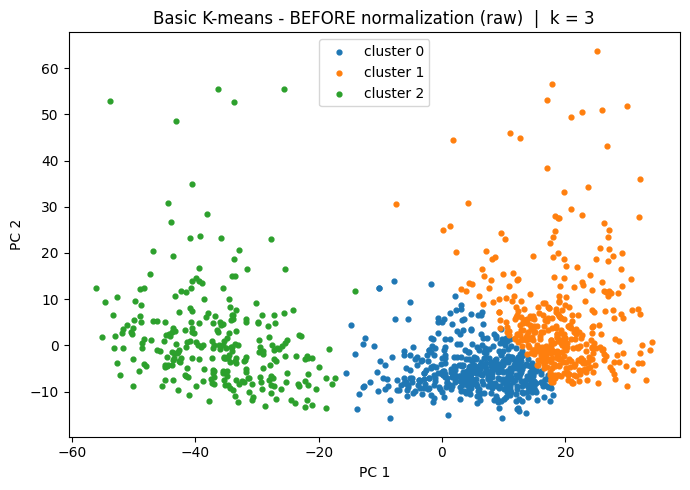


QUESTION 2 - Bisecting K-means - BEFORE normalization (raw): trying k = 3..6
  k |            SSE | avg silhouette | cluster sizes
------------------------------------------------------------
  3 |      247384.17 |         0.3204 | [278, 364, 489]
  4 |      212993.22 |         0.3152 | [278, 489, 313, 51]
  5 |      190472.50 |         0.2464 | [489, 313, 51, 148, 130]
  6 |      173416.24 |         0.1827 | [313, 51, 148, 130, 298, 191]
--> most compact clustering: k = 3 (silhouette = 0.3204, SSE = 247384.17)

Bisecting K-means - BEFORE normalization (raw)  |  k = 3

Cluster 0  (size = 278)   [class 0: 274, class 1: 4]
  Centroid:
    baseHt                 0.7632
    depth                  1.3659
    coreDepth              1.3627
    baseDiam               2.2959
    baseShear             12.0240
    baseVrot              10.8363
    baseGTGVD             13.8022
    maxShear              13.8999
    maxVrot               11.9182
    meanStrength           2.6403
    MaxStrength   

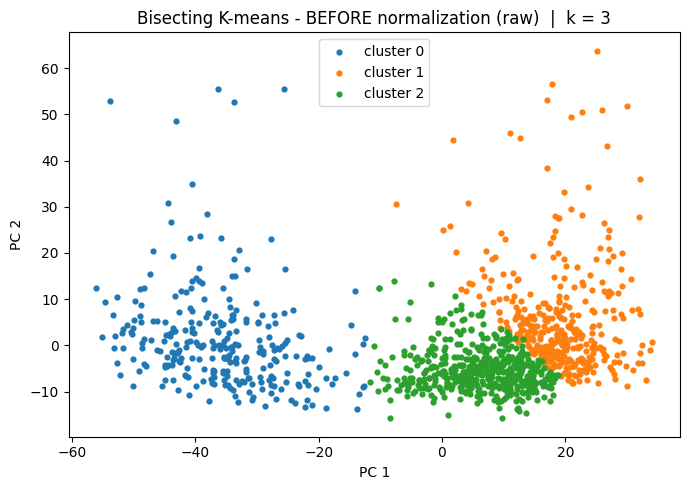


QUESTION 2 - Basic K-means - AFTER z-score normalization: trying k = 3..6
  k |            SSE | avg silhouette | cluster sizes
------------------------------------------------------------
  3 |        8068.89 |         0.3731 | [772, 106, 253]
  4 |        7093.21 |         0.2562 | [537, 60, 248, 286]
  5 |        6545.77 |         0.2170 | [47, 213, 244, 242, 385]
  6 |        5921.32 |         0.2228 | [242, 44, 244, 214, 376, 11]
--> most compact clustering: k = 3 (silhouette = 0.3731, SSE = 8068.89)

Basic K-means - AFTER z-score normalization  |  k = 3

Cluster 0  (size = 772)   [class 0: 532, class 1: 240]
  Centroid:
    baseHt                 0.2670
    depth                  0.3106
    coreDepth              0.4393
    baseDiam               0.3086
    baseShear             -0.4059
    baseVrot              -0.1433
    baseGTGVD             -0.1318
    maxShear              -0.4026
    maxVrot               -0.0620
    meanStrength          -0.1703
    MaxStrength          

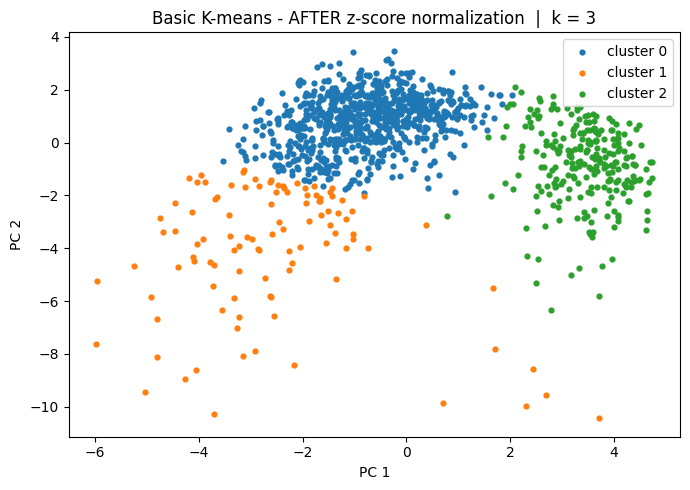


QUESTION 2 - Bisecting K-means - AFTER z-score normalization: trying k = 3..6
  k |            SSE | avg silhouette | cluster sizes
------------------------------------------------------------
  3 |        8175.61 |         0.3726 | [262, 104, 765]
  4 |        7397.07 |         0.2169 | [262, 104, 457, 308]
  5 |        6757.37 |         0.2263 | [262, 457, 308, 11, 93]
  6 |        6422.05 |         0.1713 | [262, 308, 11, 93, 195, 262]
--> most compact clustering: k = 3 (silhouette = 0.3726, SSE = 8175.61)

Bisecting K-means - AFTER z-score normalization  |  k = 3

Cluster 0  (size = 262)   [class 0: 261, class 1: 1]
  Centroid:
    baseHt                -0.7944
    depth                 -1.2221
    coreDepth             -1.5159
    baseDiam              -0.9317
    baseShear              0.9454
    baseVrot              -0.3061
    baseGTGVD             -0.3953
    maxShear               0.8713
    maxVrot               -0.5374
    meanStrength          -0.2346
    MaxStrength    

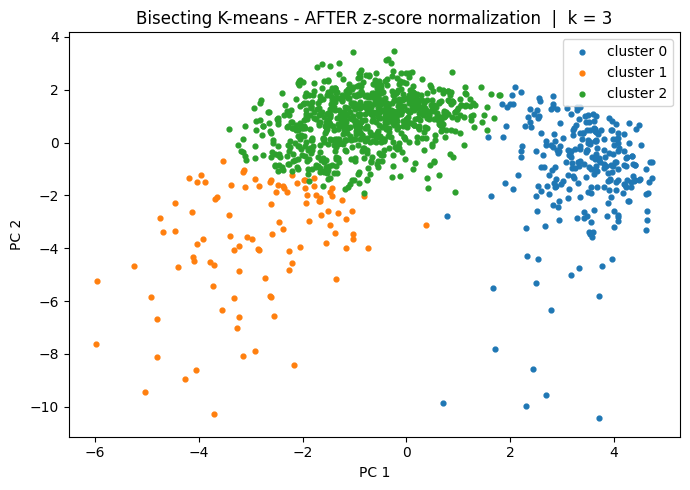


SUMMARY OF THE 4 RUNS
run                                                best k            SSE  silhouette
Basic K-means - BEFORE normalization (raw)              3      245739.50      0.3194
Bisecting K-means - BEFORE normalization (raw)          3      247384.17      0.3204
Basic K-means - AFTER z-score normalization             3        8068.89      0.3731
Bisecting K-means - AFTER z-score normalization         3        8175.61      0.3726


In [ ]:
def main():
    path = locate_data_file()
    attribute_names, data = load_arff(path)
    print(f"Loaded {data.shape[0]} patterns with {data.shape[1]} attributes from {path}")

    # The last attribute is the class label -> excluded from normalization & clustering
    class_index = attribute_names.index("class")
    feature_names = [n for i, n in enumerate(attribute_names) if i != class_index]
    class_values = data[:, class_index]
    raw_features = np.delete(data, class_index, axis=1)

    # ---------------- Question 1: z-score normalization ----------------
    normalized_features, means, stds = zscore_normalize(raw_features)

    print("\nQUESTION 1 - Z-SCORE NORMALIZATION")
    print(f"{'attribute':<18s} {'mean':>12s} {'std':>12s} {'raw min':>10s} {'raw max':>10s} "
          f"{'z min':>8s} {'z max':>8s}")
    for i, name in enumerate(feature_names):
        print(f"{name:<18s} {means[i]:12.4f} {stds[i]:12.4f} {raw_features[:, i].min():10.3f} "
              f"{raw_features[:, i].max():10.3f} {normalized_features[:, i].min():8.3f} "
              f"{normalized_features[:, i].max():8.3f}")

    print("\nFirst 5 normalized patterns (class column appended, unchanged):")
    preview = np.column_stack([normalized_features[:5], class_values[:5]])
    print(np.array2string(preview, precision=4, suppress_small=True, max_line_width=200))

    # Save the normalized data set as a new ARFF file
    out_path = "mesocyclone_zscore.arff"
    with open(out_path, "w") as out:
        out.write("@relation mesocyclone_zscore\n\n")
        for name in feature_names:
            out.write(f"@attribute {name} real\n")
        out.write("@attribute class real\n\n@data\n")
        for row, cls in zip(normalized_features, class_values):
            out.write(",".join(f"{v:.6f}" for v in row) + f",{cls:.0f}\n")
    print(f"\nNormalized data written to {out_path}")

    # ---------------- Question 2: clustering (4 runs) ----------------
    datasets = {"BEFORE normalization (raw)": raw_features,
                "AFTER z-score normalization": normalized_features}
    algorithms = {"Basic K-means": kmeans, "Bisecting K-means": bisecting_kmeans}

    summary = []
    for data_label, features in datasets.items():
        for algo_label, algo in algorithms.items():
            run_title = f"{algo_label} - {data_label}"
            results = evaluate_k_range(features, algo)
            print_k_table(results, f"QUESTION 2 - {run_title}: trying k = 3..6")
            best_k = select_most_compact(results)
            labels, centroids, sse, sil = results[best_k]
            print(f"--> most compact clustering: k = {best_k} "
                  f"(silhouette = {sil:.4f}, SSE = {sse:.2f})\n")
            display_clusters(features, labels, centroids, class_values, feature_names,
                             f"{run_title}  |  k = {best_k}")
            summary.append((run_title, best_k, sse, sil))

    print("\n" + "=" * 78)
    print("SUMMARY OF THE 4 RUNS")
    print("=" * 78)
    print(f"{'run':<50s} {'best k':>6s} {'SSE':>14s} {'silhouette':>11s}")
    for run_title, best_k, sse, sil in summary:
        print(f"{run_title:<50s} {best_k:>6d} {sse:14.2f} {sil:11.4f}")


main()

## 8. Discussion

**Effect of normalization.** On the raw data the Euclidean distance is dominated by `meanReflectivity` / `maxReflectivity` (std ≈ 15–17) and the shear / GTGVD attributes, while `baseHt`, `coreDepth` and the strength attributes (std ≈ 1–3) barely influence the partition. After z-scoring every attribute has unit variance, so each one contributes equally. The total SSE drops ~30× purely because the scale changed, which is why SSE must never be compared *between* the raw and normalized runs – only *within* one run across *k*.

**Choosing k.** In all four runs the silhouette peaks at *k* = 3 and falls for *k* = 4…6, so *k* = 3 gives the most compact, best-separated grouping. The normalized runs reach a higher silhouette (≈ 0.37 vs ≈ 0.32): the clusters are cleaner once no single attribute dominates.

**K-means vs. bisecting K-means.** Both find essentially the same three groups (a shallow, low-reflectivity group; a strong / deep, high-reflectivity group; and a middle group). Basic K-means attains slightly lower SSE because every centroid is free to move at every iteration, while bisecting K-means commits to each split and only refines within it. In exchange bisecting K-means is less sensitive to initialization, yields a nested (hierarchical) structure, and its larger-*k* results are consistent refinements of the smaller-*k* ones.

**Suitability.** K-means assumes roughly spherical, similarly sized clusters and is sensitive to outliers – the few extreme shear / strength readings (z > 7) pull centroids and spawn tiny clusters at *k* ≥ 5. Z-score normalization fits this data because the attributes are continuous with very different ranges; it is less appropriate for attributes that are already on a common scale, and for heavy-tailed attributes a robust scaler (median / IQR) or min-max may behave better.